# Imports

In [1]:
import numpy as np
import random
from scipy import stats
from collections import defaultdict
import matplotlib.pyplot as plt
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Constants

In [2]:
NUM_AGENTS = 10
NUM_ACTIONS = 5
HORIZON = 100
N_TRIALS = 100
MAX_REWARD_ABS_VAL = 10.0
MIN_Z_I = 80,
MAX_Z_I = 150
MIN_P_I = 0.2
MAX_P_I = 0.8

# Policies

In [3]:
class EpsilonGreedy:
    def __init__(self, epsilon, num_actions, name="Epsilon Greedy"):
        self.name = name
        self.epsilon = epsilon
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        if self.rng.random() < self.epsilon:
            return int(self.rng.choice(active_actions))

        best_value = max(self.q[a] for a in active_actions)
        best = [a for a in active_actions if self.q[a] == best_value]
        return int(self.rng.choice(best))


class Boltzmann:
    def __init__(self, temperature, num_actions, name="Boltzmann"):
        self.name = name
        self.temperature = temperature
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        q_values = np.array([self.q[a] for a in active_actions])
        logits = (q_values - np.max(q_values)) / self.temperature

        exp_q = np.exp(logits)
        probabilities = exp_q / np.sum(exp_q)

        return int(self.rng.choice(active_actions, p=probabilities))


class UCB:
    def __init__(self, c, num_actions, name="UCB"):
        self.name = name
        self.c = c
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.t = 0

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        self.t += 1
        unvisited = [a for a in active_actions if self.n[a] == 0]

        if unvisited:
            return int(self.rng.choice(unvisited))

        ucb_values = {
            a: self.q[a] + self.c * np.sqrt(np.log(self.t) / self.n[a])
            for a in active_actions
        }

        best_value = max(ucb_values.values())
        best = [a for a in active_actions if ucb_values[a] == best_value]
        return int(self.rng.choice(best))


class Thompson:
    def __init__(self, num_actions, name="Thompson Policy"):
        self.name = name
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.m2 = {a: 0.0 for a in range(num_actions)}

    def update(self, a, r):
        n = self.n[a] + 1
        old_mean = self.q[a]
        new_mean = old_mean + (r - old_mean) / n

        self.m2[a] += (r - old_mean) * (r - new_mean)

        self.q[a] = new_mean
        self.n[a] = n

    def select(self, active_actions):
        samples = []
        for a in active_actions:
            if self.n[a] < 2:
                std = 1.0
            else:
                std = np.sqrt(self.m2[a] / (self.n[a] - 1) / self.n[a])
                std = max(std, 1e-6)

            samples.append(self.rng.normal(self.q[a], std))

        return int(active_actions[np.argmax(samples)])


class GradientBandit:
    def __init__(self, alpha, num_actions, name="Gradient Bandit"):
        self.name = name
        self.alpha = alpha

        self.h = {a: 0.0 for a in range(num_actions)}
        self.reward_sum = {a: 0.0 for a in range(num_actions)}
        self.reward_count = {a: 0 for a in range(num_actions)}

        self.avg_r = 0.0
        self.active_actions = []
        self.probabilities = {}

    def update(self, a, r, active_actions):
        self.reward_sum[a] += r
        self.reward_count[a] += 1

        total_sum = sum(self.reward_sum[x] for x in active_actions)
        total_count = sum(self.reward_count[x] for x in active_actions)

        self.avg_r = total_sum / total_count if total_count else 0.0
        for action in active_actions:
            if action == a:
                self.h[action] += (
                    self.alpha * (r - self.avg_r)
                    * (1 - self.probabilities[action])
                )
            else:
                self.h[action] -= (
                    self.alpha * (r - self.avg_r)
                    * self.probabilities[action]
                )

    def select(self, active_actions):
        self.active_actions = list(active_actions)

        logits = np.array([self.h[a] for a in active_actions])
        logits -= np.max(logits)

        exp_h = np.exp(logits)
        probs = exp_h / np.sum(exp_h)

        self.probabilities = dict(zip(active_actions, probs))

        return int(self.rng.choice(active_actions, p=probs))

For each algorithm I implemented three functions: init, update and select. The algorithms are initialized in init. The name of the algorithm along with any necessary hyperparameters are given in this function. In the update function, a sample reward and action are given to the algorithm so it could update its paramaters such as the value functions. In the select function, the algorithms selects an action among the given active actions.

To make sure the algorithms worked with disabling actions the only change I needed to do was to limit the action pool during action selection. However for gradient bandit, I also modified it to use the average reward of only the actions that are currently available. To do this, I stored the count and sum of rewards for each action.

# Environment

In [4]:
class Environment:
    def __init__(self, rng, num_actions):
        self.rng = rng
        self.r_max_i = rng.uniform(0, MAX_REWARD_ABS_VAL, num_actions)
        self.r_min_i = rng.uniform(-MAX_REWARD_ABS_VAL, 0, num_actions)
        self.p_i = rng.uniform(MIN_P_I, MAX_P_I, num_actions)
        self.z_i = rng.integers(MIN_Z_I, MAX_Z_I+1, num_actions)
        self.w_i = self.z_i * self.r_max_i 
        self.active = np.ones(num_actions, dtype=bool)

    def step(self, action):
        success = self.rng.random() < self.p_i[action]
        reward = self.r_max_i[action] if success else self.r_min_i[action]
        if reward > 0:
            self.z_i[action] -= 1
            self.w_i[action] -= self.r_max_i[action]
            if self.z_i[action] <= 0:
                self.active[action] = False
        return reward

# Agent

In [5]:
class Agent:
    def __init__(self, num_actions, policy, rng):
        self.num_actions = num_actions
        self.policy = policy
        self.policy.rng = rng

    def select(self, active):
        return self.policy.select(active)

    def update(self, a, r, active):
        if isinstance(self.policy, GradientBandit):
            self.policy.update(a, r, active)
        else:
            self.policy.update(a, r)

# Experiment

In [6]:
def run_trial(num_actions, policies, L, seed):
    algo_names = list(dict.fromkeys(policy.name for policy in policies))
    algo_counts = {
        name: sum(1 for p in policies if p.name == name)
        for name in algo_names
    }

    ss = np.random.SeedSequence(seed)
    env_seed, order_seed, agent_seed, reward_seed = ss.spawn(4)
    env_rng = np.random.default_rng(env_seed)
    order_rng = np.random.default_rng(order_seed)
    agent_seeds = np.random.default_rng(agent_seed).spawn(len(policies))

    env = Environment(env_rng, num_actions)
    agents = [
        Agent(num_actions, policy, np.random.default_rng(agent_seeds[i]))
        for i, policy in enumerate(policies)
    ]

    r_round = np.zeros(L)
    cum_population = np.zeros(L)
    cum_agent = np.zeros((len(agents), L))
    cum_algo = {name: np.zeros(L) for name in algo_names}
    n_active = np.zeros(L)
    remaining_z = np.zeros((L+1, num_actions))
    remaining_z[0] = env.z_i
    pull_counts  = np.zeros((L, num_actions), dtype=int)

    running_person = np.zeros(len(agents))
    running_algo = {name: 0.0 for name in algo_names}

    for t in range(L):
        order = order_rng.permutation(len(agents))
        rewards = np.zeros(len(agents))

        for idx in order:
            agent = agents[idx]
            active_actions = np.where(env.active)[0]

            if len(active_actions) == 0:
                break

            action = agent.select(active_actions)
            reward = env.step(action)
            agent.update(action, reward, active_actions)

            pull_counts[t, action] += 1
            rewards[idx] = reward
            running_person[idx] += reward
            running_algo[policies[idx].name] += reward

        r_round[t] = rewards.mean()
        cum_agent[:, t] = running_person

        for name in algo_names:
            cum_algo[name][t] = running_algo[name] / algo_counts[name]

        cum_population[t] = running_person.sum()
        n_active[t] = np.sum(env.active)
        remaining_z[t+1] = env.z_i

    return {
        "r_round":        r_round,
        "cum_population": cum_population,
        "cum_agent":      cum_agent,
        "cum_algo":       cum_algo,
        "n_active":       n_active,
        "remaining_z":    remaining_z,
        "action_value":   env.p_i * env.r_max_i + (1-env.p_i) * env.r_min_i,
        "pull_counts":  pull_counts,
    }

In [7]:
def mean_ci(arr_2d, confidence=0.95):
    n_trials = arr_2d.shape[0]
    m = arr_2d.mean(axis=0)
    se = arr_2d.std(axis=0, ddof=1) / np.sqrt(n_trials)
    h = se * stats.t.ppf((1 + confidence) / 2, n_trials - 1)
    return m, h

def plot_mean_ci(x, mean, half_width, title, label=None, ax=None, alpha=0.2, ylim=None):
    ax = ax or plt.gca()
    ax.plot(x, mean, label=label)
    ax.fill_between(x, mean - half_width, mean + half_width, alpha=alpha)
    ax.set_xlabel("Round"); ax.set_ylabel(title); ax.set_title(title+" per Round")
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.grid(alpha=0.3)

The confidence interval is computed by considering the t-student distribution. The reason for using t-student instead of normal is so that the confidence interval would work even with few samples and if the are a lot of samples the two would become almost the same. We can assume t-student or normal because the metrics are averages so we could use CLT.

# Finding Hyperparameters

In [8]:
reward = {}
for eps in np.linspace(0.01, 1.0, 100):
    policy = (EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[eps] = np.mean(cum_agent)
eps = float(max(reward, key=reward.get))
eps

0.43

In [9]:
reward = {}
for tau in np.linspace(0.01, 3.0, 100):
    policy = (Boltzmann(temperature=tau, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[tau] = np.mean(cum_agent)
tau = float(max(reward, key=reward.get))
tau

0.3120202020202021

In [10]:
reward = {}
for alpha in np.linspace(0.01, 1.0, 100):
    policy = (GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[alpha] = np.mean(cum_agent)
alpha = float(max(reward, key=reward.get))
alpha

0.18000000000000002

To select the hyperparameters, I ran each algorithm alone 100 times for 100 values and selected the optimal value for the hyperparameter. Although this doesn't necessraily mean the hyperparameter will also be optimal with the other algorithms, but I chose this method because it was less expensive to run and less wouldn't get leakage info from the main experiment.

# A) Heterogeneous Population

In [11]:
def run_trials(policy_factories, n_trials, horizon, num_actions, W=10):
    results = []
    for seed in range(n_trials):
        results.append(
            run_trial(
                num_actions,
                [f() for f in policy_factories],
                horizon,
                seed
            )
        )

    algo_names = list(results[0]["cum_algo"].keys())
    order = np.argsort(
        -np.stack([r["action_value"] for r in results]),
        axis=1
    )

    remaining_z = np.stack([r["remaining_z"] for r in results])
    remaining_z_sorted = np.take_along_axis(
        remaining_z,
        order[:, None, :],
        axis=2
    )

    pull_counts = np.stack([r["pull_counts"] for r in results])
    pulls_sorted = np.take_along_axis(
        pull_counts,
        order[:, None, :],
        axis=2
    )

    cumsum = np.cumsum(pulls_sorted, axis=1)
    window = cumsum.copy()
    window[:, W:, :] -= cumsum[:, :-W, :]

    agents = results[0]["cum_agent"].shape[0]
    rounds_so_far = np.minimum(np.arange(1, horizon + 1), W)
    denom = agents * rounds_so_far

    window_frac = window / denom[None, :, None]

    return {
        "algo_names": algo_names,

        "r_round": mean_ci(
            np.stack([r["r_round"] for r in results])
        ),
        "n_active": mean_ci(
            np.stack([r["n_active"] for r in results])
        ),
        "cum_population": mean_ci(
            np.stack([r["cum_population"] for r in results])
        ),
        "cum_agent": mean_ci(
            np.stack([r["cum_agent"] for r in results])
        ),
        "cum_algo": {
            name: mean_ci(
                np.stack([r["cum_algo"][name] for r in results])
            )
            for name in algo_names
        },
        "raw_cum_algo": {
            name: np.stack([r["cum_algo"][name] for r in results])
            for name in algo_names
        },
        "remaining_z": mean_ci(remaining_z_sorted),
        "window_frac": mean_ci(window_frac),
        "W": W,
    }

In [12]:
def report_results(res, num_actions):
    horizon = len(res["n_active"][0])
    rounds = np.arange(1, horizon + 1)
    rounds_snap = np.arange(0, horizon + 1)

    for key, title, ylim in [
        ("r_round", "Average Reward", None),
        ("n_active", "Number of Active Actions", (0, num_actions * 1.1)),
        ("cum_population", "Cumulative Reward of Population", None),
    ]:
        fig, ax = plt.subplots(figsize=(9, 6))
        plot_mean_ci(
            rounds, *res[key], title, ax=ax, ylim=ylim
        )
        fig.tight_layout()
        plt.show()

    plots = [
        (res["cum_algo"], rounds, "Cumulative Reward per Agent"),
        (res["remaining_z"], rounds_snap, r"Remaining success budget $z_i$"),
        (res["window_frac"], rounds, f"Pull share over last {res['W']} rounds"),
    ]
    for i, (data, x, title) in enumerate(plots):
        fig, ax = plt.subplots(figsize=(9, 6))
        if i == 0:
            for name in res["algo_names"]:
                plot_mean_ci(
                    x, *data[name], title,
                    label=name, ax=ax, alpha=0.1
                )
        else:
            for r in range(num_actions):
                plot_mean_ci(
                    x,
                    data[0][:, r],
                    data[1][:, r],
                    title,
                    label=f"Rank {r + 1}",
                    ax=ax,
                    alpha=0.12
                )

        ax.legend()
        fig.tight_layout()
        plt.show()

In [13]:
def run_and_report(policies, n_trials=N_TRIALS,
                   horizon=HORIZON, num_actions=NUM_ACTIONS):
    res = run_trials(policies, n_trials, horizon, num_actions)
    report_results(res, num_actions)
    return res

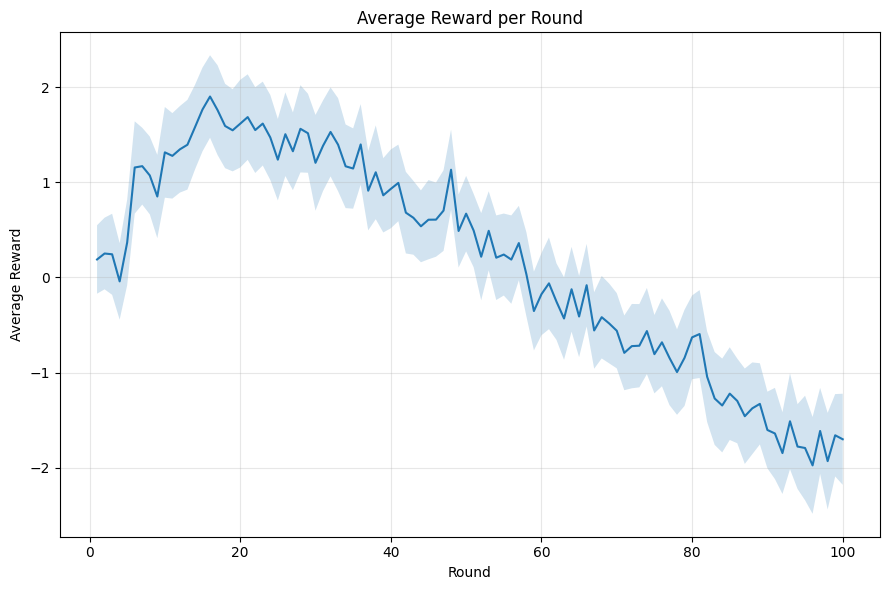

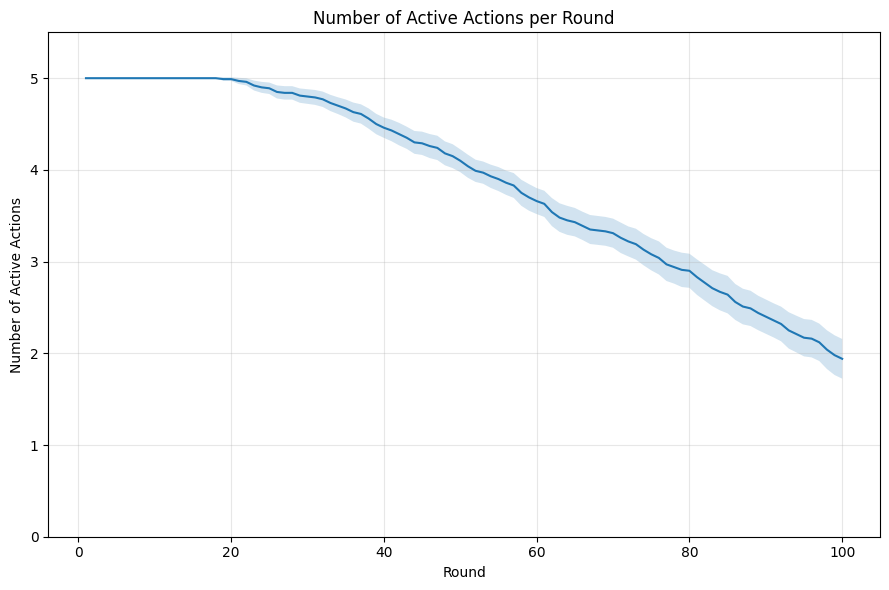

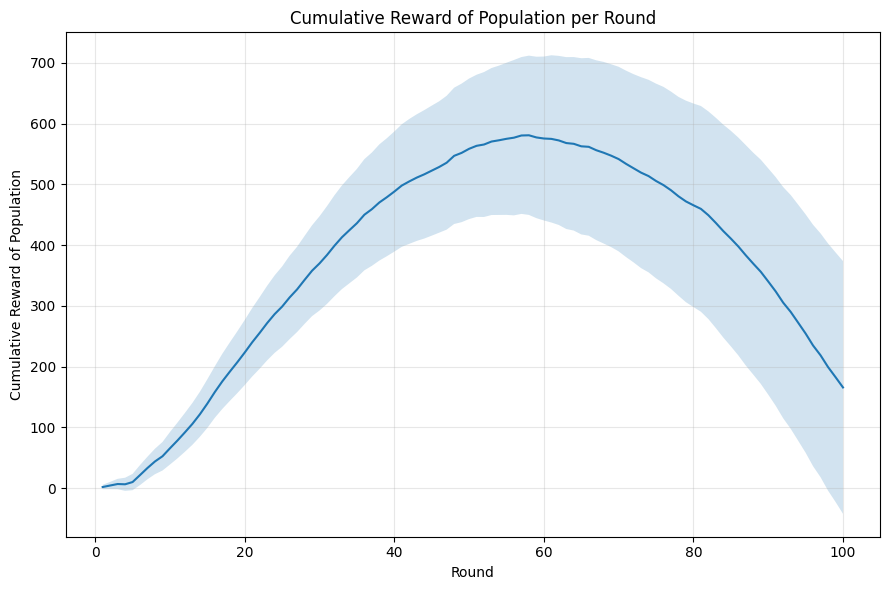

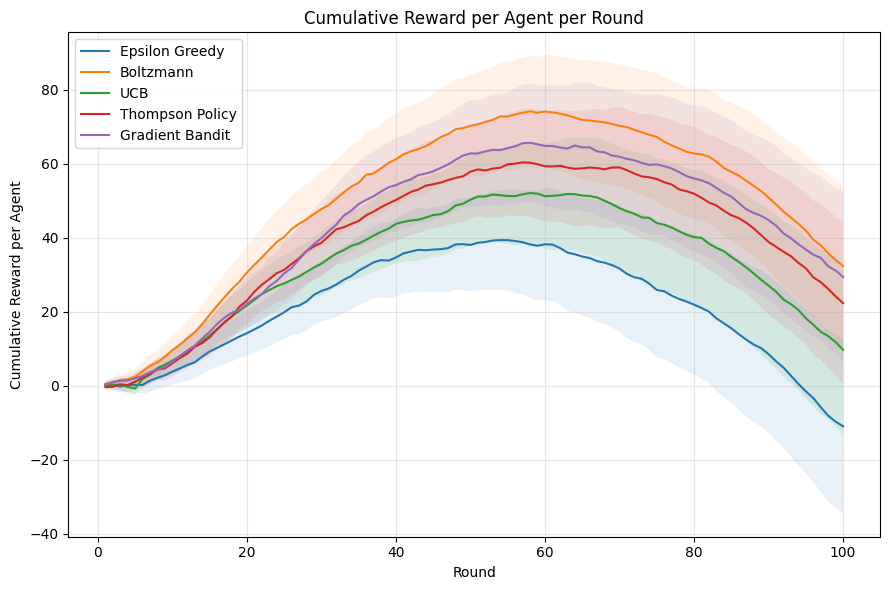

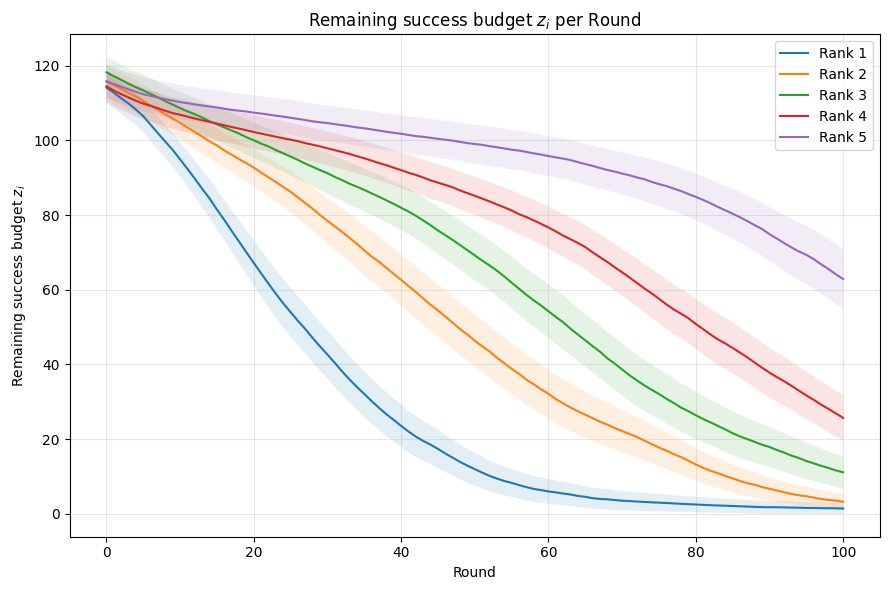

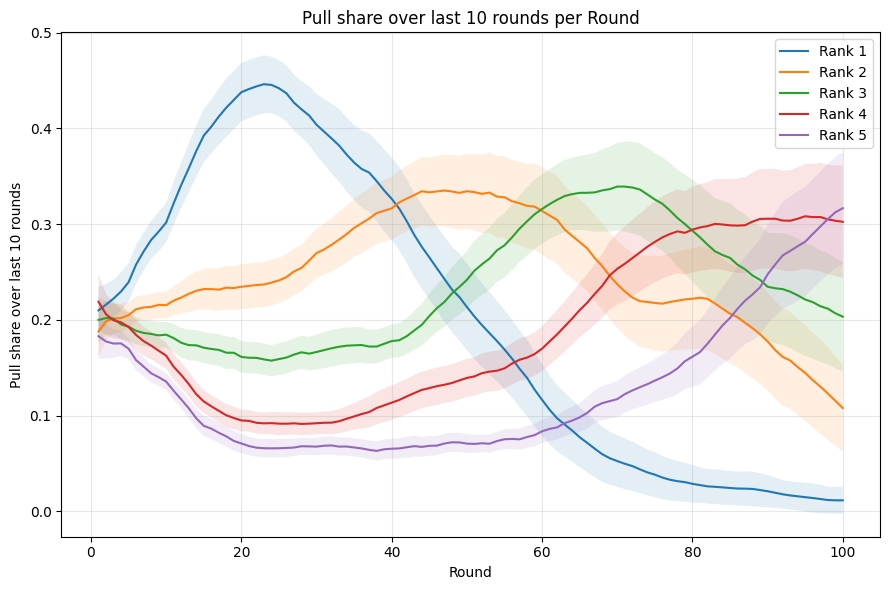

In [14]:
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

hetero_res = run_and_report(policies)

Based on the selected hyperparameters here the Boltzmann algorithm had the highest individual reward followed by Gradient Bandit. Epsilon Greedy with constant epsilon performed the worst followed by UCB.

From the remaining success budget plot it is obvious that the most valuable resource is consumed at a faster pace and almost always ends up being finished, followed by the second action which is almost always finished. The third action with highest expected reward however never finishes while the fourth and fifth actions are also selected a good amount of times.

From the share of pulls plot, we can see only a significant difference in the first action not the othres, such that the total number of other actions all start increasing almost together.

* How does the reward of the population change and what is the reason?

The average reward keeps increasing until about the 15th round. After that it starts decreasing going negative from round 60. Consequently, the cumulative reward of the population starts decreasing from the 60th round until the end.

The reason may be due to the limited amount of resources, after the valuable resources with great $p_i$ and $r_{max,i}$ finish the agents will be forced to select less valuable resources and after some point only the resources with $p_i < 0.5$ will remain which cause an overall negative reward.

* How do disabled actions affect the algorithms' behavior?

As expected, the number of enabled actions keeps decreasing with the first action becoming disabled some wher around the 20th to 55th round. As the number of available actions decreases, the models are forced to select less valuable actions and get less reward. So the best algorithm here not only should detect the optimal action but also it should detect the next optimal actions to be able to be successful overall.

* Does a successful algorithm have a positive impact on the population?

Not necessarily, for example a successful algorithm may always detect the best ation and select it but the other algorithms may only be able to detect the optimal action once. The successful algorithm would cause the optimal resource to finish faster thus from that point on, the other actions would hurt the society. Thus each action's self successful performance doesn't necessarily have an overall positive impact on the society.

* Why would we need to modify the current Bandit algorithms for this problem?

There are several reasons for this including the fact that the number of active actions change after some time, thus the environment is not static which is assumed to be true for these algorithms. Also by designing algorithms that are aware of the existence of the other agents, we may be able to increase the society's overall benefit.

* How can the hyperparameters of the algorithms affect the results?

These hyperparameters determine the amount of risk the agent would be willing to take and the balance between eploration and eplotation. For example by exploring more, the agent may get behind the other algorithms for a while but it could correctly rank the actions thus it may perform better after the optimal action gets disabled, on the other hand exploiting earlier could benefit the agent which is in compete with the others for the optimal action.

# B) Social Regret

1. Can we use the standard single-agent Bandit algorithms in here without any modifications?

The standard regret shouldn't be used in here because the goal is different. In the standard bandit algorithm, the goal is to maximize the cumulative reward by selecting the optimal action. But here the shared goal among all the agents is maximizing the cumulative reward of all the agents so individual maximization may not necessarily cause overall maximization of cumulative reward.

2. Considering the limited resource pool and influence of action selection on other agents, what would the optimal action or policy mean in here?

These two factors have a direct impact on each agent's expected reward for each action.

3. Does maximization of individual reward cause the maximization of population reward?

Not necessarily. if all agents select the optimal action, after it finishes they need to spend time exploring to find the second best action and that could cost negative rewards. If instead they could coordinate such that agent i would only consume the ith optimal action or select among a subset of actions then each action needs to search in a much smaller action space thus the total cumulative reward could increase.

4. Give a proper definition for **Social Regret** and indicate what the optimal policy needs other than the basic info about the actions to select the best action? Only reasoning is enough and there is no need for implementation of the optimal policy.

First let's remember the mathematical definition of **Regret**:
$$
R = E[r(a^*)]T-\Sigma_{i=1}^{n}{E[T_i]\,E[r(a_i)]}
$$
Where $T$ is the total number of rounds, $T_i$ is the expected number of rounds that the ith action is selected, $a^*$ is the optimal action in the sense that it has the most expected reward, $r(a_i)$ is the random variable representing the reward received from selection the ith action. 

I defined the **Social Regret** as:
$$
SR = \Sigma_{i=1}^{A}{E[r(a^*)]T\,A-\Sigma_{j=1}^{n}{E[T_{i,j}]\,E[r(a_i)]}} = E[r(a^*)]T\,A-\Sigma_{i=1}^{A}\Sigma_{j=1}^{n}{E[T_{i,j}]\,E[r(a_i)]}
$$

Where $A$ represents the number of agents. The above formula assumes there is no limitaion in selecting any actions, if there are such as it is the case in this assignment, then we could change the definition by considering using all the resources of optimal action then continuing with the second optimal action and so on so the first term would change.

It's obvious from the above definition that in theory local maximization of each agent causes minimization of social regret however, in practice the indirect interaction of agents and the heterogenesioty of their algorithms causes this rule not to be true any more.

# C) Homogeneous Popoulation

## Eps-Greedy

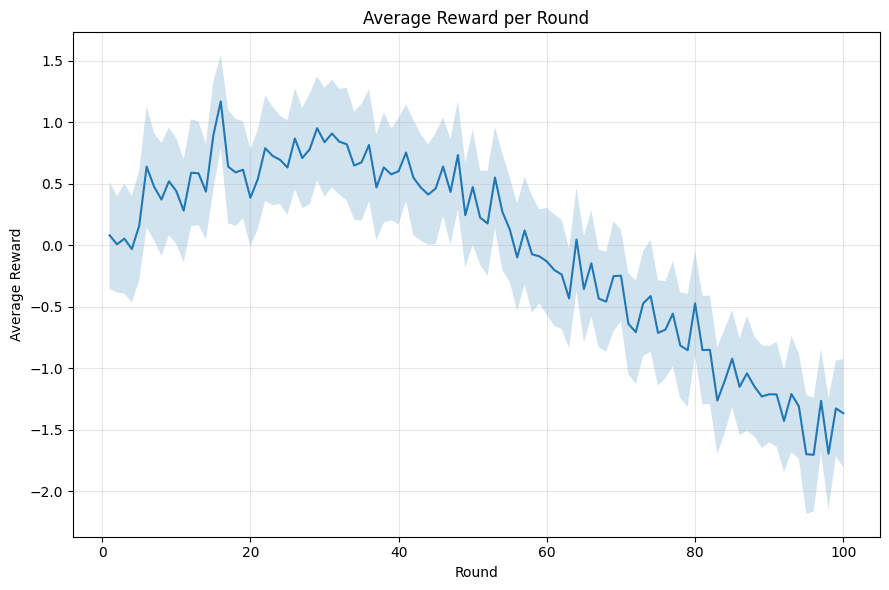

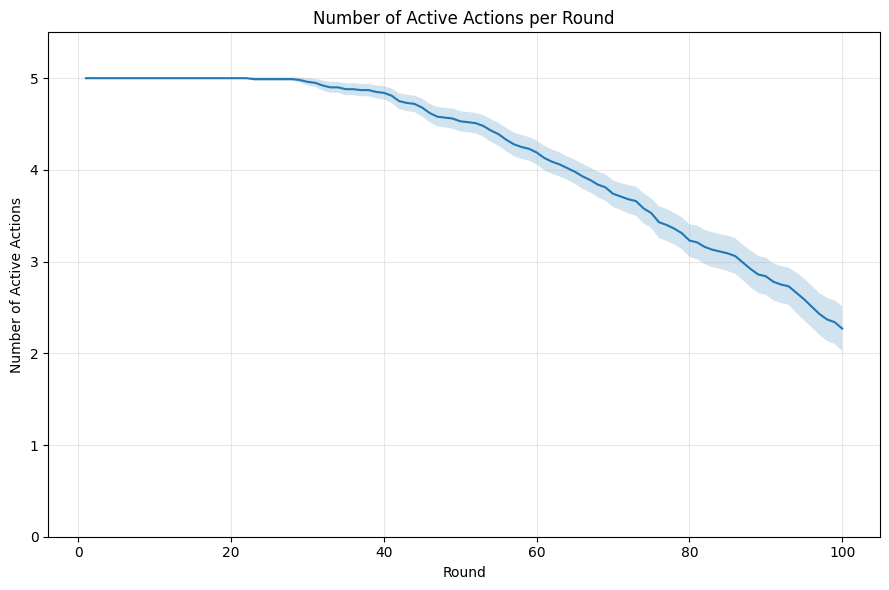

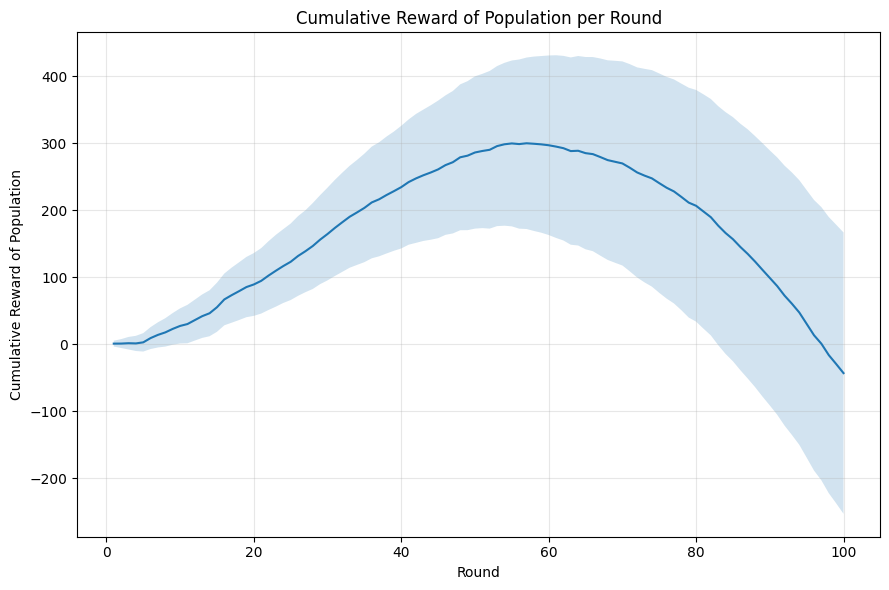

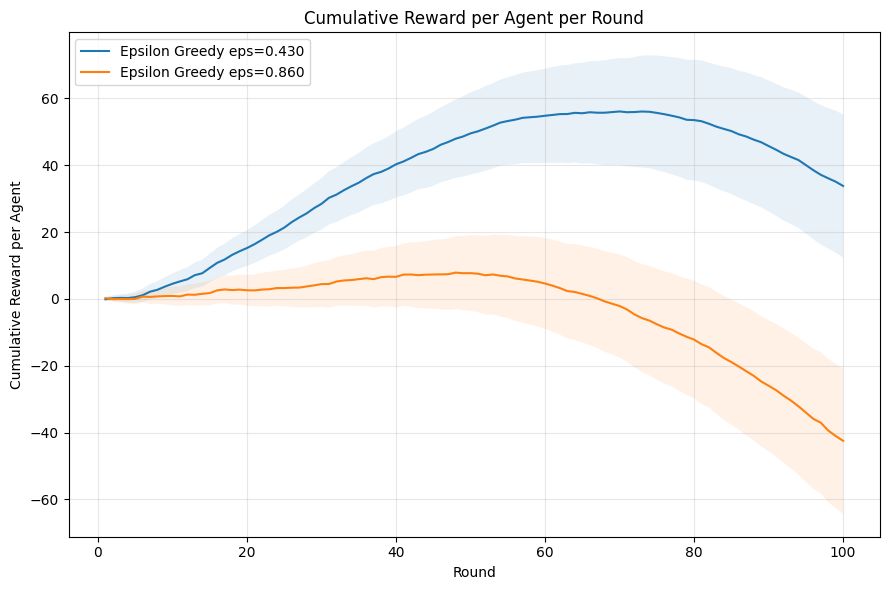

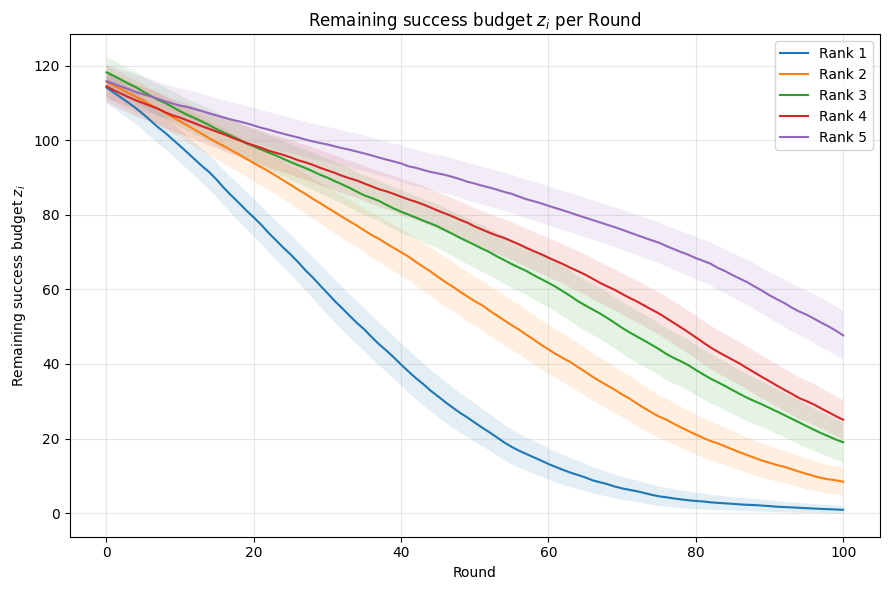

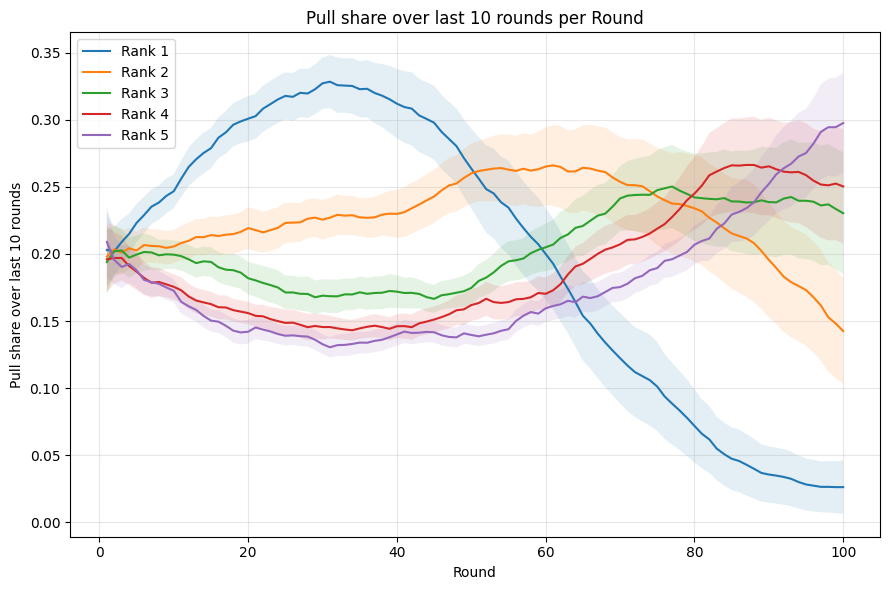

In [15]:
policies = []
eps2 = 2*eps
for _ in range(5):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps:.3f}"))
    policies.append(lambda: EpsilonGreedy(epsilon=eps2, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps2:.3f}"))

eg_res = run_and_report(policies)

## UCB

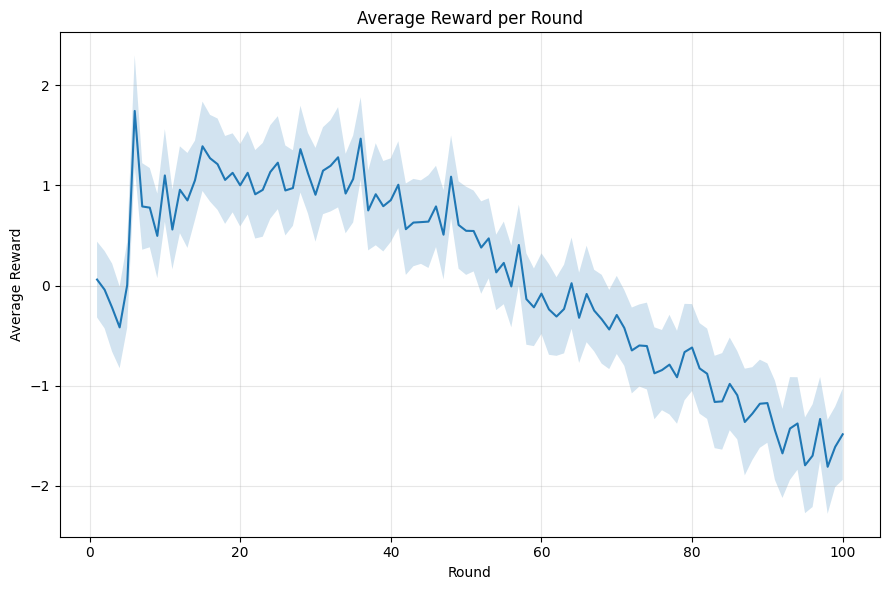

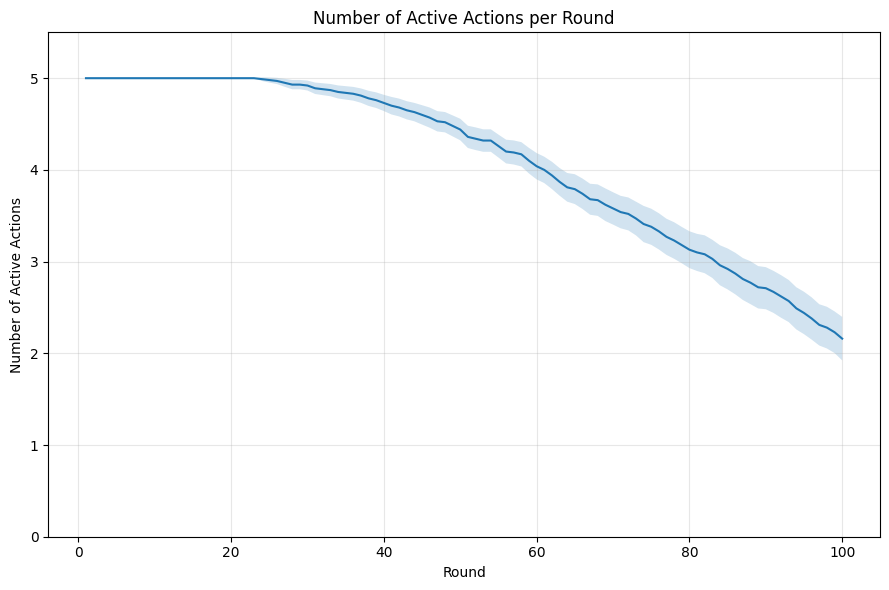

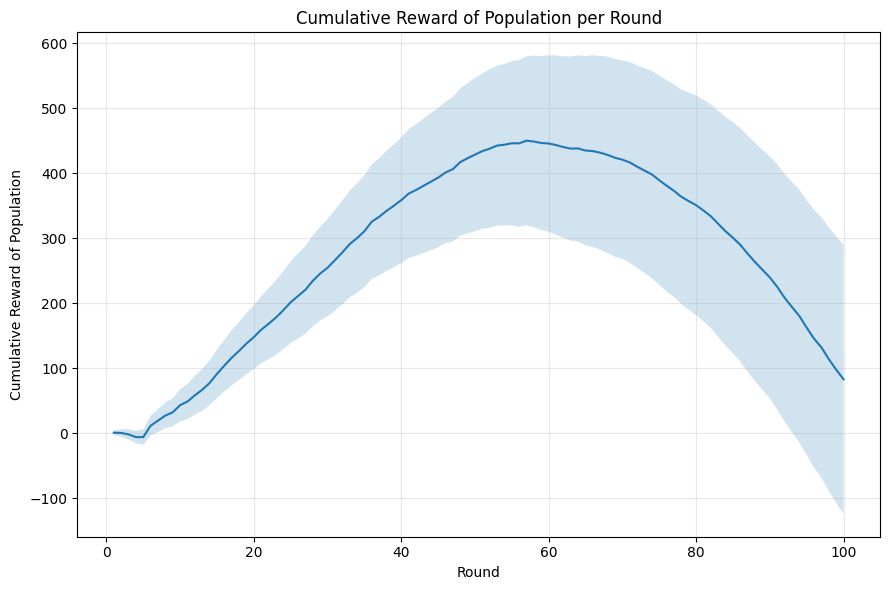

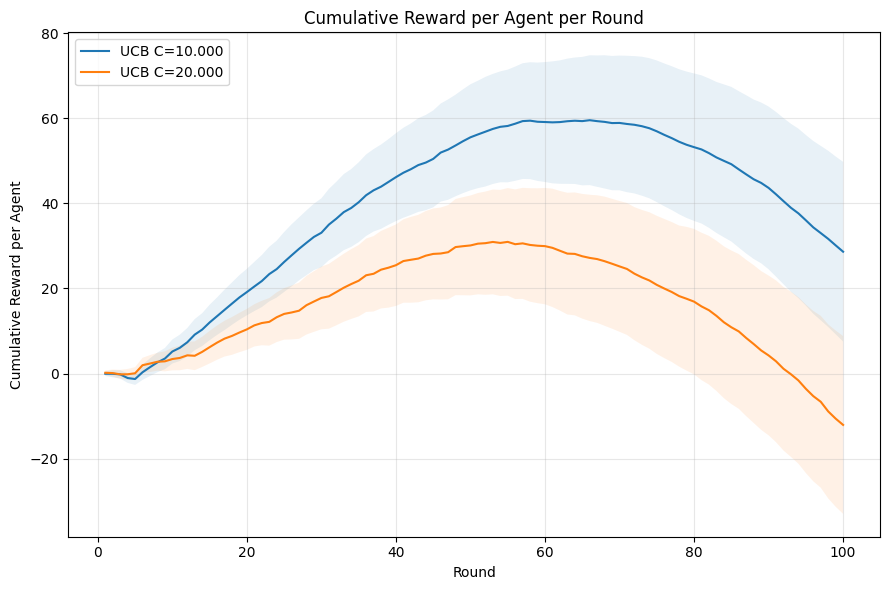

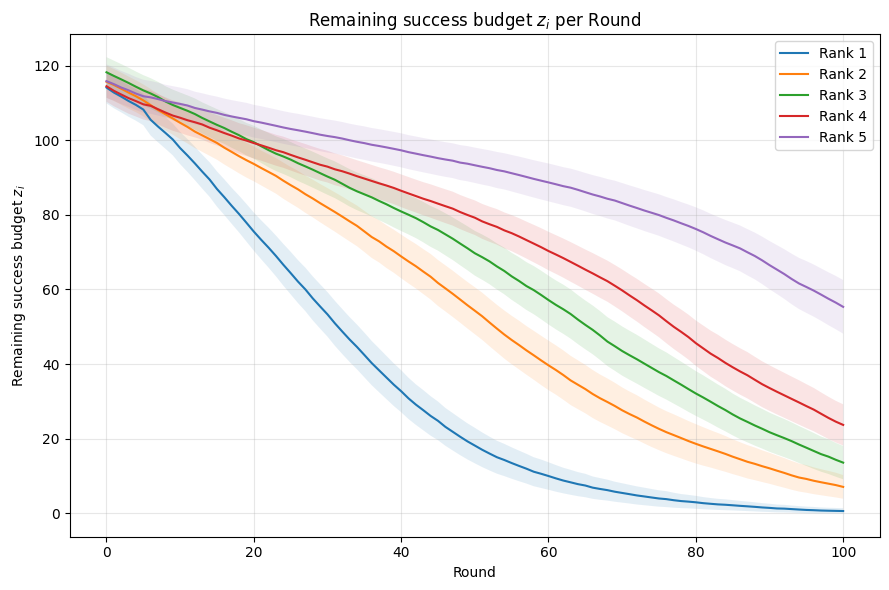

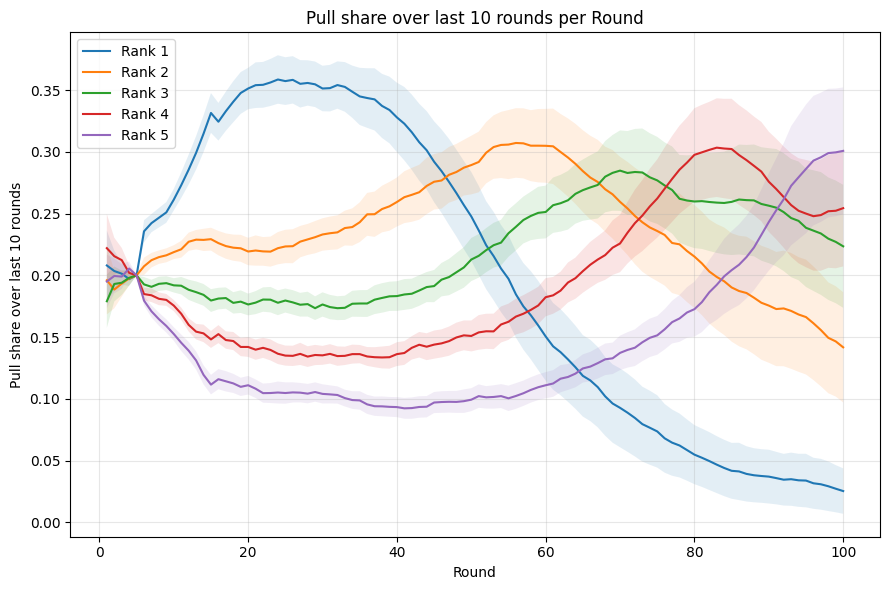

In [16]:
policies = []
c2 = 2*MAX_REWARD_ABS_VAL
for _ in range(5):
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS, name=f"UCB C={MAX_REWARD_ABS_VAL:.3f}"))
    policies.append(lambda: UCB(c=c2, num_actions=NUM_ACTIONS, name=f"UCB C={c2:.3f}"))

ucb_res = run_and_report(policies)

## Gradient Bandit

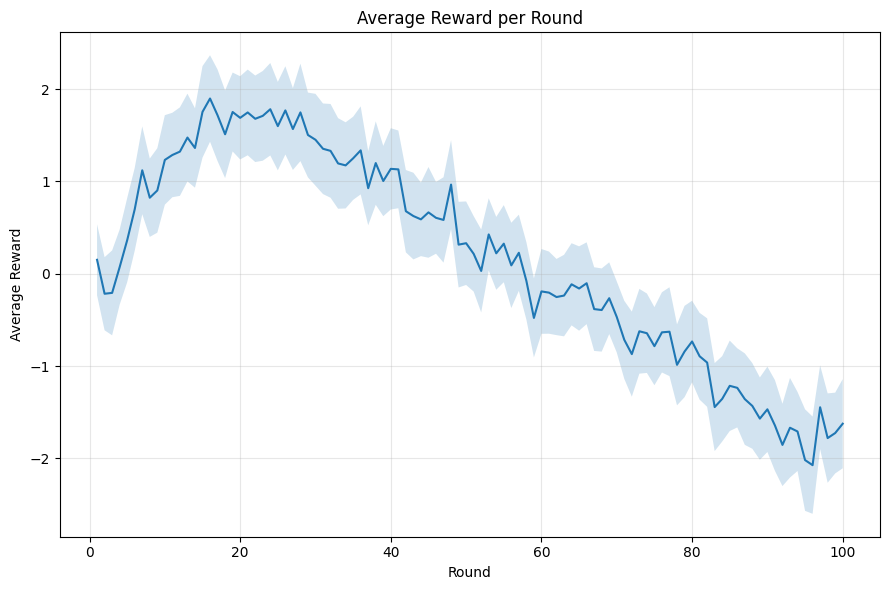

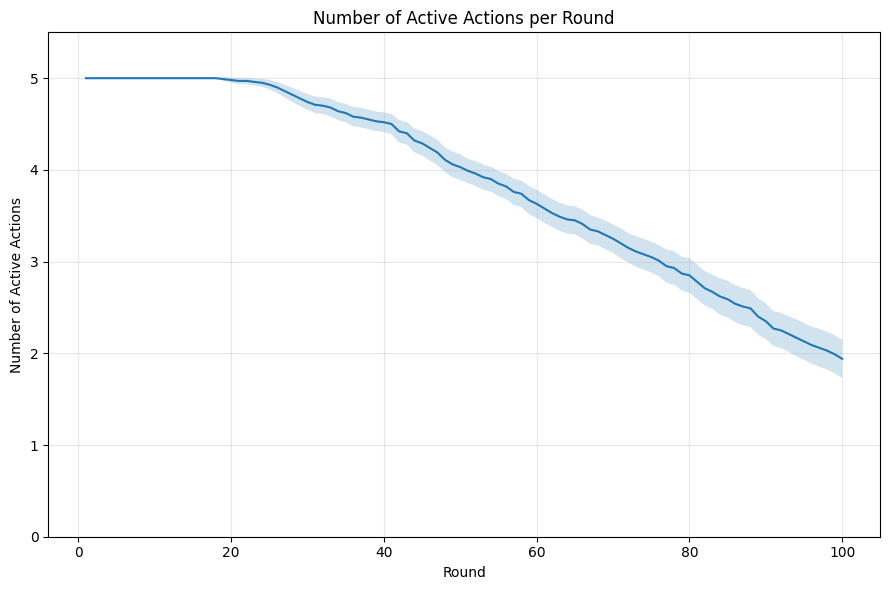

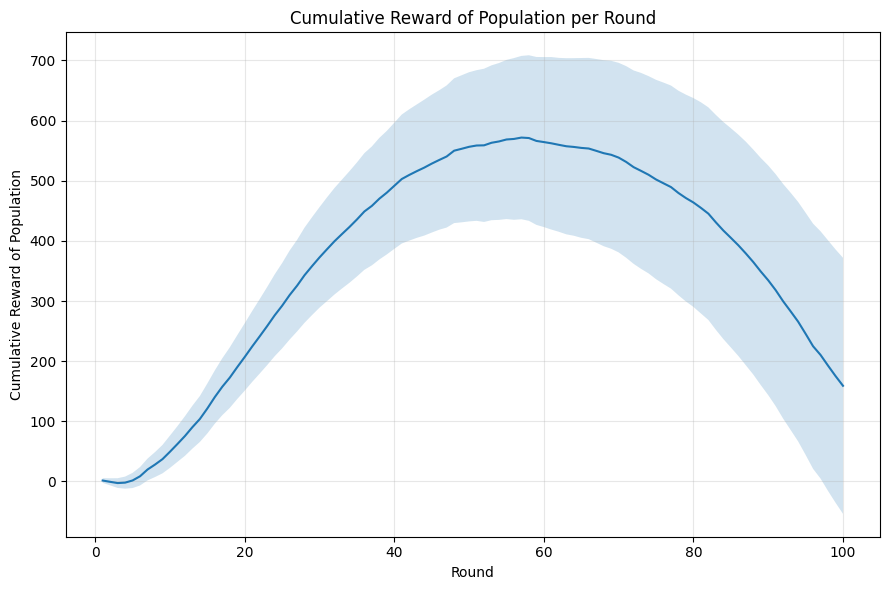

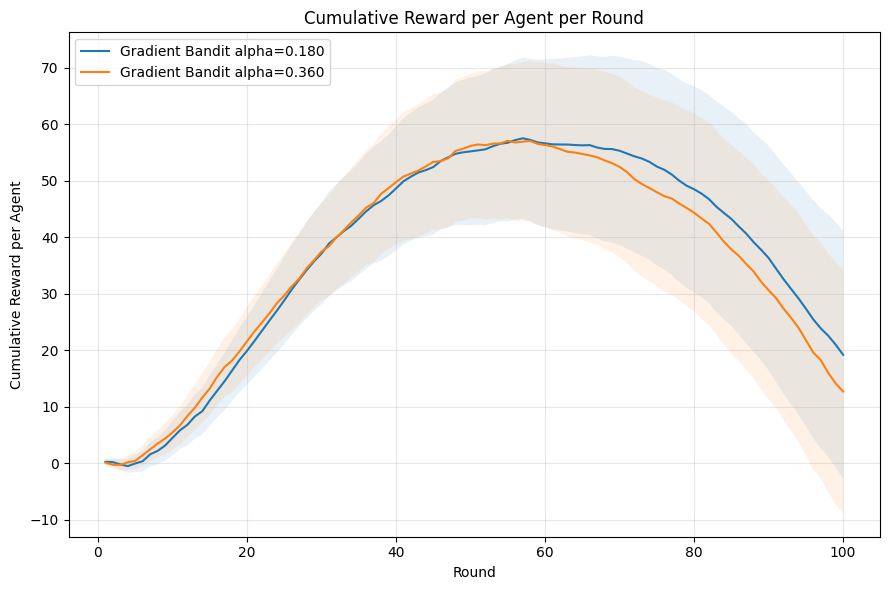

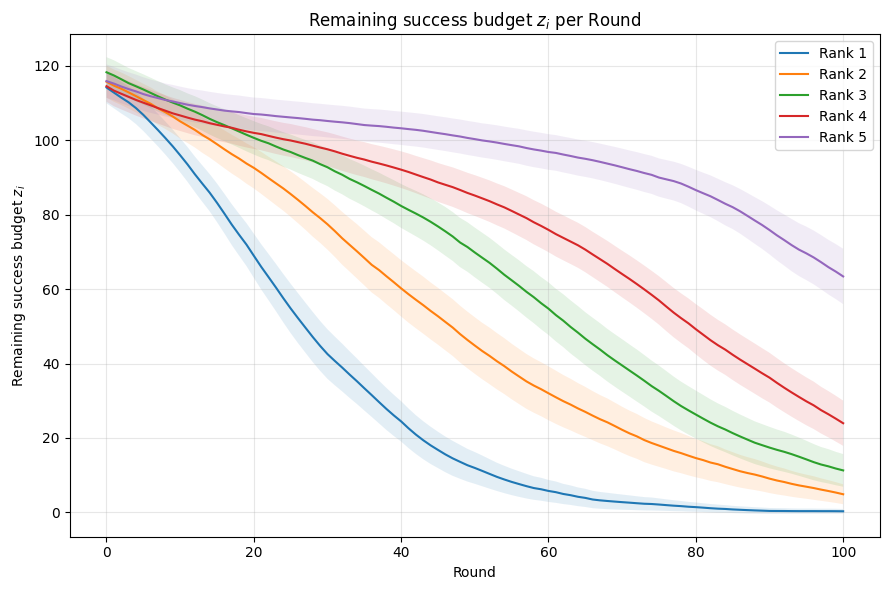

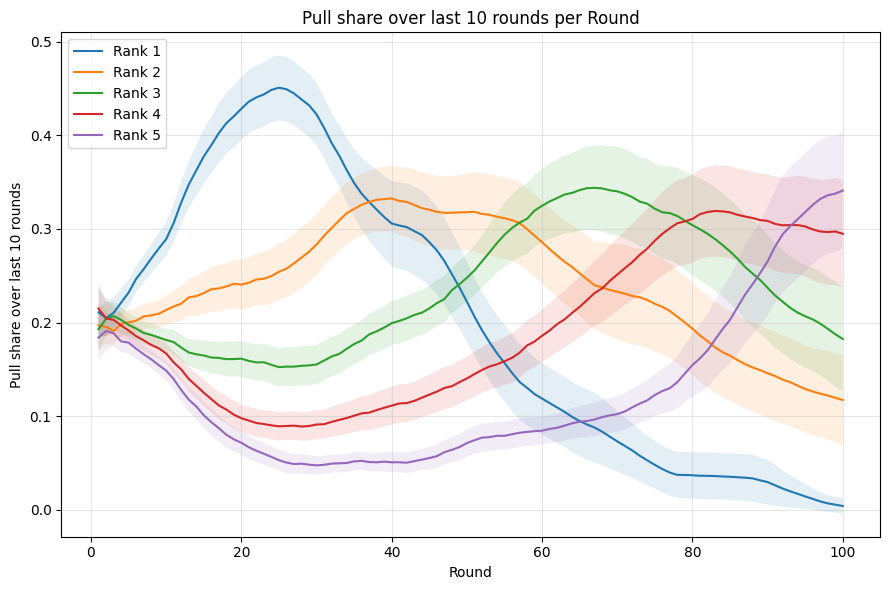

In [17]:
policies = []
alpha2 = 2*alpha
for _ in range(5):
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS, name=f"Gradient Bandit alpha={alpha:.3f}"))
    policies.append(lambda: GradientBandit(alpha=alpha2, num_actions=NUM_ACTIONS, name=f"Gradient Bandit alpha={alpha2:.3f}"))

gb_res = run_and_report(policies)

## Analysis

* Does the algorithm which receives rewards faster in the beginning, perform better in the end as well?

By comparing the average cumulative reward per algorithm, we can see that although in the beginning an algorithm may receive more rewards after some point the other algorithms starts outperforming and keeps being better until the end. The reason may be due to exploration-explotation balance such that an algorithm that explores much more, would receive less rewards in the beginning but after finding the optimal action would keep being better.

* How does the speed of consuming resources affect the final cumulative reward?
We can see the agent with greater final cumulative reward is the with higher peak thus it seems like faster resource consumption causes greater final cumulative reward.

* Is the difference between algorithms statistically siginficant?

Let's perform statistical tests:

In [18]:
configs = {
    "Epsilon-Greedy":  list(eg_res["raw_cum_algo"].keys())[0],
    "UCB":             list(ucb_res["raw_cum_algo"].keys())[0],
    "Gradient Bandit": list(gb_res["raw_cum_algo"].keys())[0],
}

scores = {
    "Epsilon-Greedy":  eg_res ["raw_cum_algo"][configs["Epsilon-Greedy"]] [:, -1],
    "UCB":             ucb_res["raw_cum_algo"][configs["UCB"]]            [:, -1],
    "Gradient Bandit": gb_res ["raw_cum_algo"][configs["Gradient Bandit"]][:, -1],
}

comparisons = []
for name1, name2 in combinations(scores.keys(), 2):
    x = scores[name1]
    y = scores[name2]

    t_stat, p_value = stats.ttest_rel(x, y)
    differences     = x - y

    comparisons.append({
        "Algorithm 1":     name1,
        "Algorithm 2":     name2,
        "Mean difference": differences.mean(),
        "t-statistic":     t_stat,
        "p-value":         p_value,
        "Cohen's dz":      differences.mean() / differences.std(ddof=1),
    })

first_tests = pd.DataFrame(comparisons)
first_tests["p-adjusted"]  = multipletests(first_tests["p-value"], method="holm")[1]
first_tests["Significant"] = first_tests["p-adjusted"] < 0.05

display(first_tests.sort_values("p-adjusted"))

,Algorithm 1,Algorithm 2,Mean difference,t-statistic,p-value,Cohen's dz,p-adjusted,Significant
1,Epsilon-Greedy,Gradient Bandit,14.646101,4.407625,0.000027,0.440763,0.000080,True
2,UCB,Gradient Bandit,9.496016,3.876493,0.000191,0.387649,0.000381,True
0,Epsilon-Greedy,UCB,5.150084,1.854419,0.066656,0.185442,0.066656,False


Based on the statistical testing results, the epsilon greedy and UCB algorithms aren't much different in performance with the given hyperparameters.

* How much do the results depend on the algorithm configs?

In [19]:
def compare_algorithms(res, alpha=0.05):
    raw = res["raw_cum_algo"]
    scores = {
        name: values[:, -1]
        for name, values in raw.items()
    }

    comparisons = []
    for name1, name2 in combinations(scores.keys(), 2):
        x = scores[name1]
        y = scores[name2]

        t_stat, p_value = stats.ttest_rel(x, y)
        differences = x - y
        effect_size = differences.mean() / differences.std(ddof=1)
        comparisons.append({
            "Algorithm 1": name1,
            "Algorithm 2": name2,
            "Mean difference": differences.mean(),
            "t-statistic": t_stat,
            "p-value": p_value,
            "Cohen's dz": effect_size,
        })

    df = pd.DataFrame(comparisons)
    df["p-adjusted"] = multipletests(
        df["p-value"],
        alpha=alpha,
        method="holm"
    )[1]
    df["Significant"] = df["p-adjusted"] < alpha
    return df.sort_values("p-adjusted")

eg_tests = compare_algorithms(eg_res)
ucb_tests = compare_algorithms(ucb_res)
gb_tests = compare_algorithms(gb_res)

display(eg_tests)
display(ucb_tests)
display(gb_tests)


,Algorithm 1,Algorithm 2,Mean difference,t-statistic,p-value,Cohen's dz,p-adjusted,Significant
0,Epsilon Greedy eps=0.430,Epsilon Greedy eps=0.860,76.257759,14.869102,5.681097e-27,1.48691,5.681097e-27,True


,Algorithm 1,Algorithm 2,Mean difference,t-statistic,p-value,Cohen's dz,p-adjusted,Significant
0,UCB C=10.000,UCB C=20.000,40.747537,11.104669,4.332445e-19,1.110467,4.332445e-19,True


,Algorithm 1,Algorithm 2,Mean difference,t-statistic,p-value,Cohen's dz,p-adjusted,Significant
0,Gradient Bandit alpha=0.180,Gradient Bandit alpha=0.360,6.510555,1.398667,0.165038,0.139867,0.165038,False


For each homogeneous experiment, I performed test along with computing the Cohen's dz of the new config, with double the value for its hyperparameter, with the previous one. Epsilon greedy had the most drop of about -2.3, followed by UCB with a drop of -1.4, followed by Gradient bandit with a drop of -0.3. Same as the statistical testing, it seems like the drop of gradient bandit is actually the lowest so it's less sensitive to 

# Measure sensitivity

## K = 30

I believe by increasing the number of agents, the resources would finish faster thus the algorithms need to find the optimal actions fast enough or else they would need to select worse actions so I expect more local difference between algorithms but faster ending of total resources.

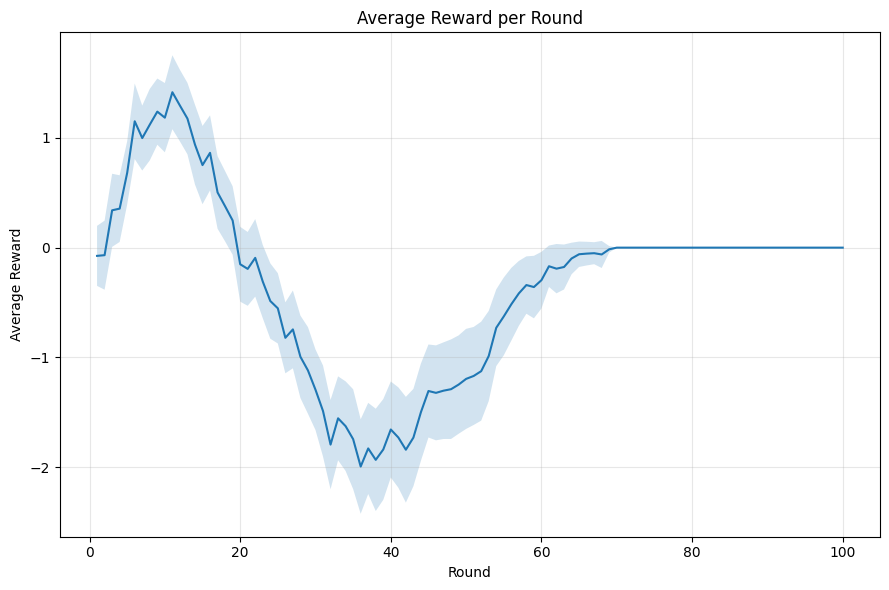

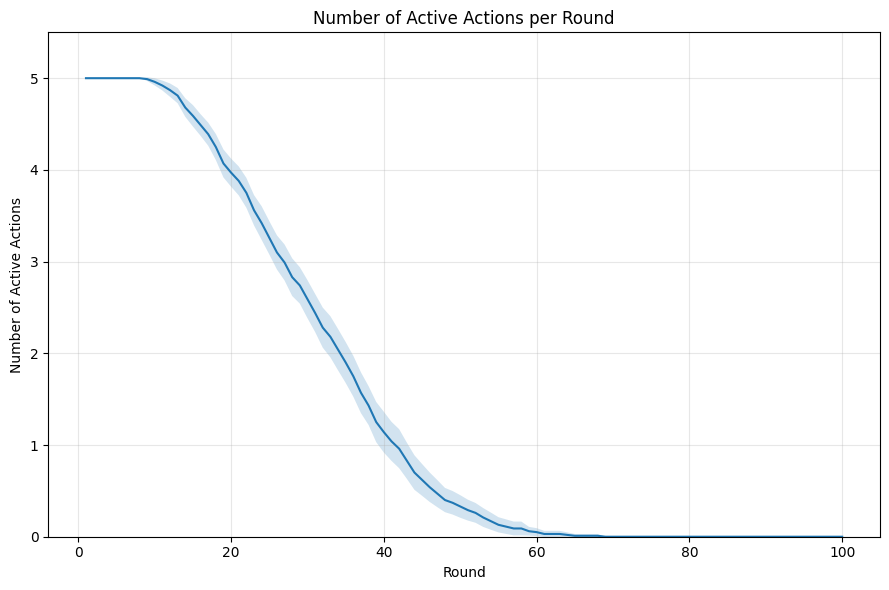

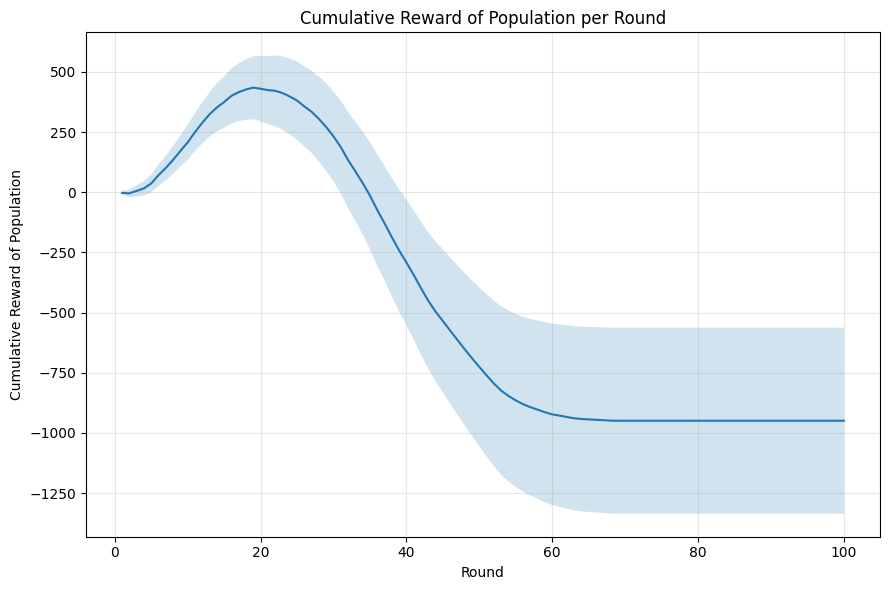

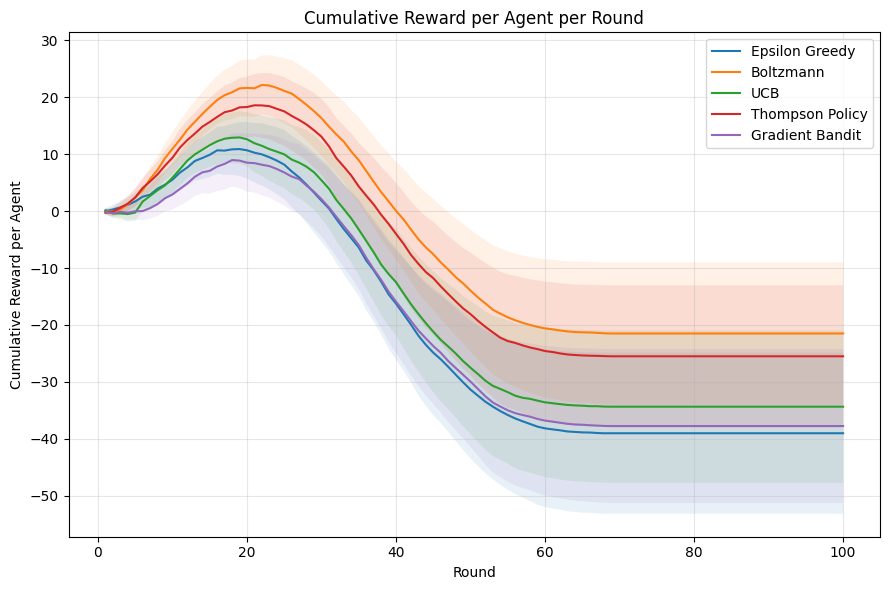

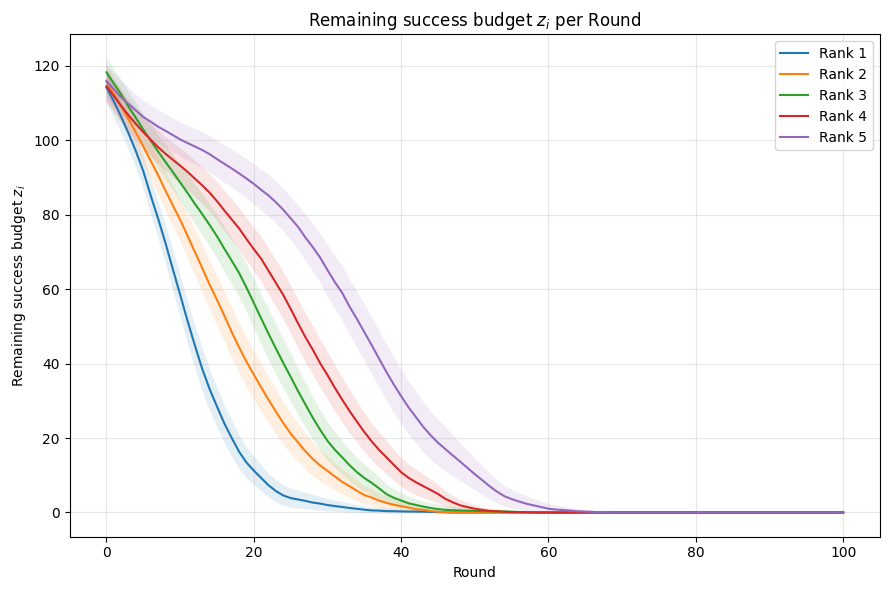

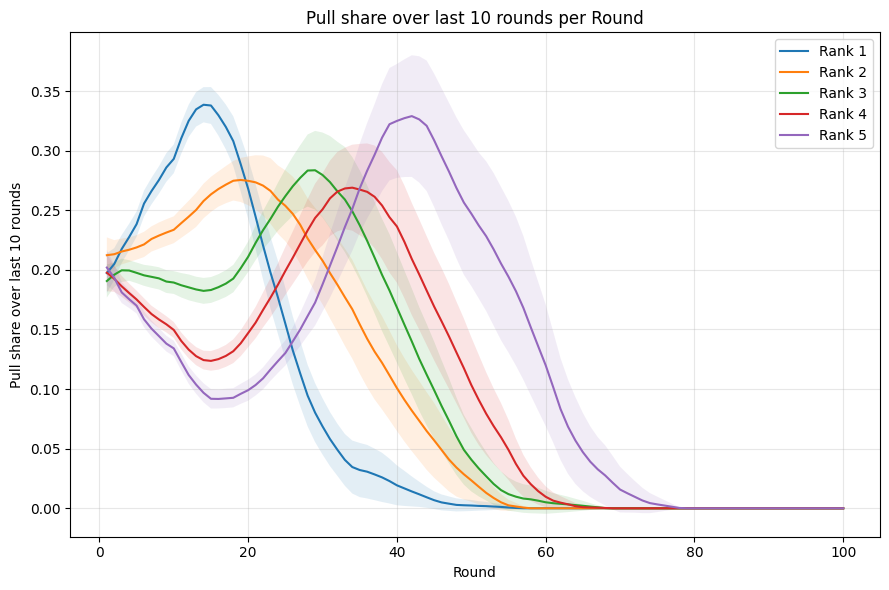

{'algo_names': ['Epsilon Greedy',
  'Boltzmann',
  'UCB',
  'Thompson Policy',
  'Gradient Bandit'],
 'r_round': (array([-0.07489221, -0.06853725,  0.34024008,  0.3555668 ,  0.68186109,
          1.15139309,  0.99838089,  1.12082629,  1.23933741,  1.18444245,
          1.41617677,  1.29467918,  1.17614366,  0.93905591,  0.75224713,
          0.86381827,  0.50303442,  0.3770538 ,  0.24765681, -0.15099391,
         -0.19345694, -0.09304708, -0.30906171, -0.48614907, -0.55284611,
         -0.82150659, -0.74495673, -0.99455306, -1.11887007, -1.29442308,
         -1.48892021, -1.79452318, -1.55502884, -1.6266455 , -1.74502803,
         -1.99441406, -1.82938774, -1.93357568, -1.83913409, -1.65695585,
         -1.72978981, -1.84132528, -1.73074412, -1.49871462, -1.30617949,
         -1.32307335, -1.30320508, -1.2896412 , -1.24802417, -1.19576728,
         -1.16920015, -1.12548807, -0.98758729, -0.7300539 , -0.62659257,
         -0.51599355, -0.41674759, -0.34075138, -0.35901666, -0.29637693,


In [ ]:
policies = []
for _ in range(6):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

k_res = run_and_report(policies)

The average expected reward starts increasing after decreasing for a while which at first seemed surprising but then I understood that it's due to missing and selecting the ignored valuable resources. Also from the pull share plot we can see a peak in the worst action in around the 40th round, that is when the other actions are almost finished so the algorithms would all start selecting the worst action.

## $z_i \sim U_{discrete}\{1,2,...,150\}$

By decreasing the minimum possible amount for $z_i$ I expect more varied results thus greater confidence intervals. Also the overall cumulative reward should be lower because resources finish faster thus more knowledge about the correct rank of actions is necessary.

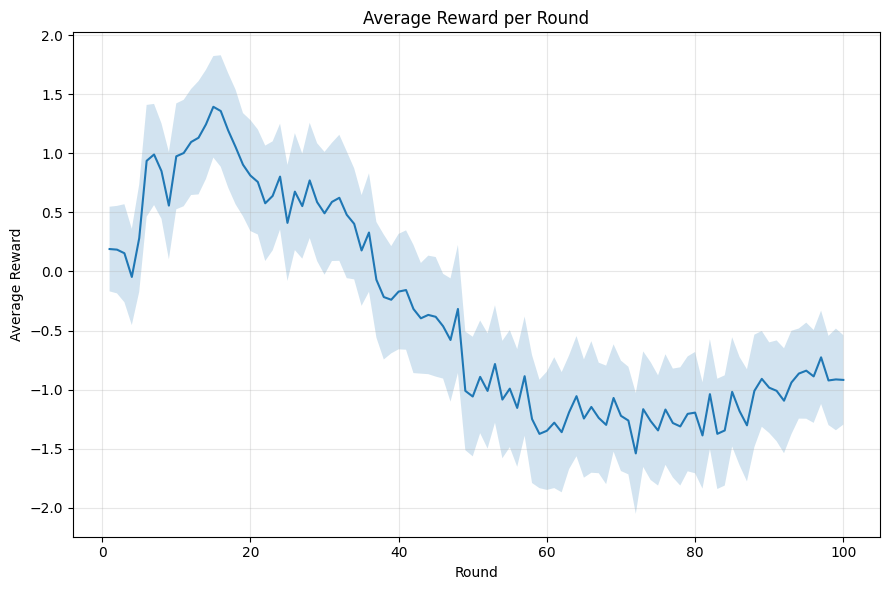

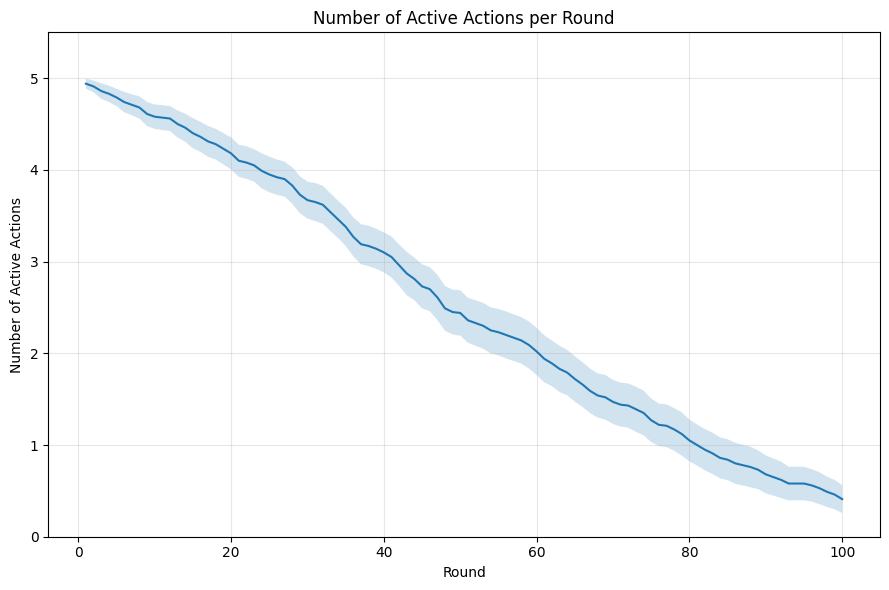

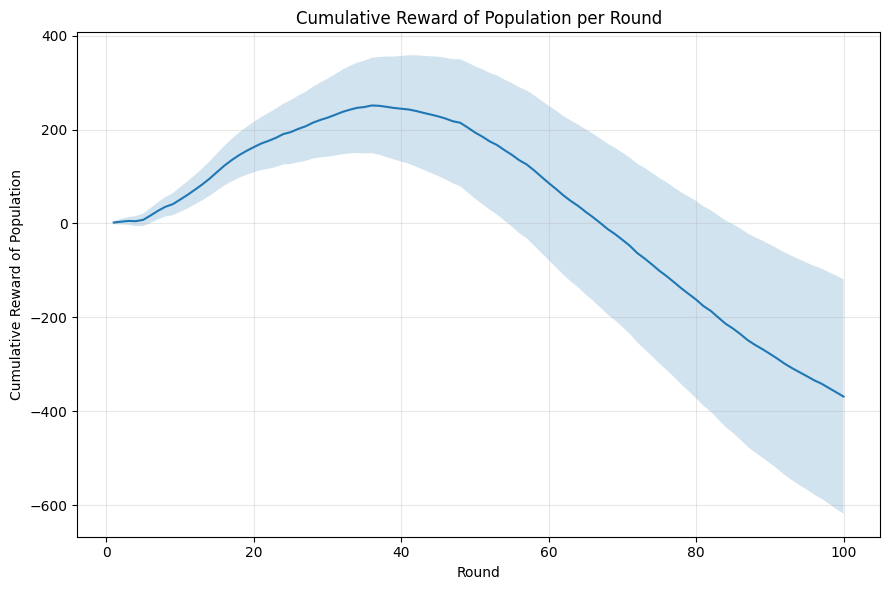

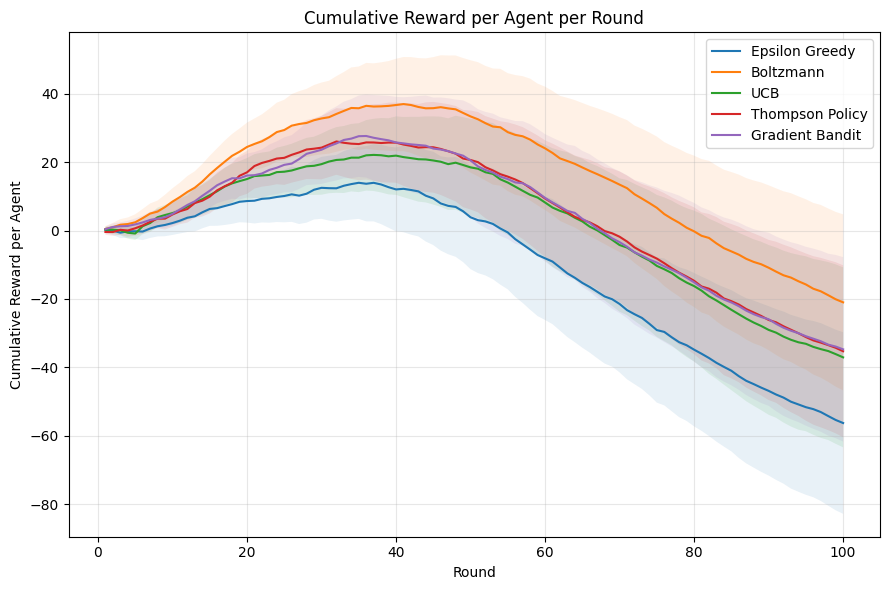

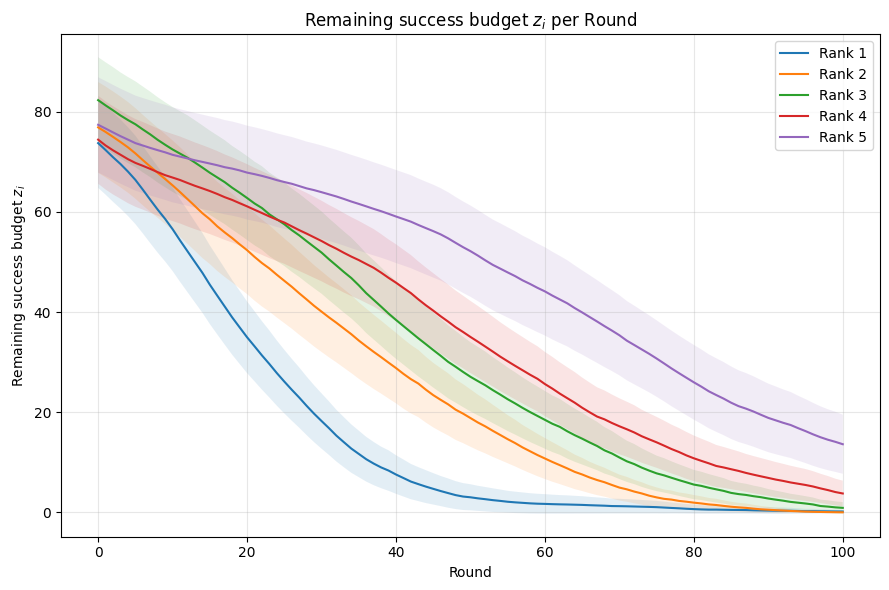

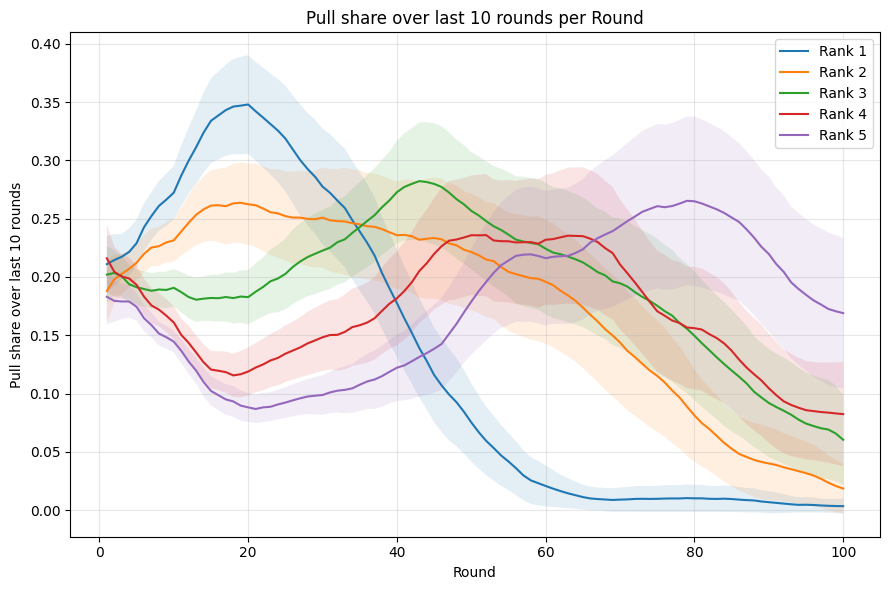

In [ ]:
MIN_Z_I = 1
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

z_res = run_and_report(policies)
MIN_Z_I = 0.8

My predictions were mostly correct.

## $p_i \sim U\{0.05,0.8\}$

I expect greater confidence intervals due to more variation in p. Also because some actions become more deterministic, I expect the agents to find optimal actions faster, thus I expect higher cumulative rewards.

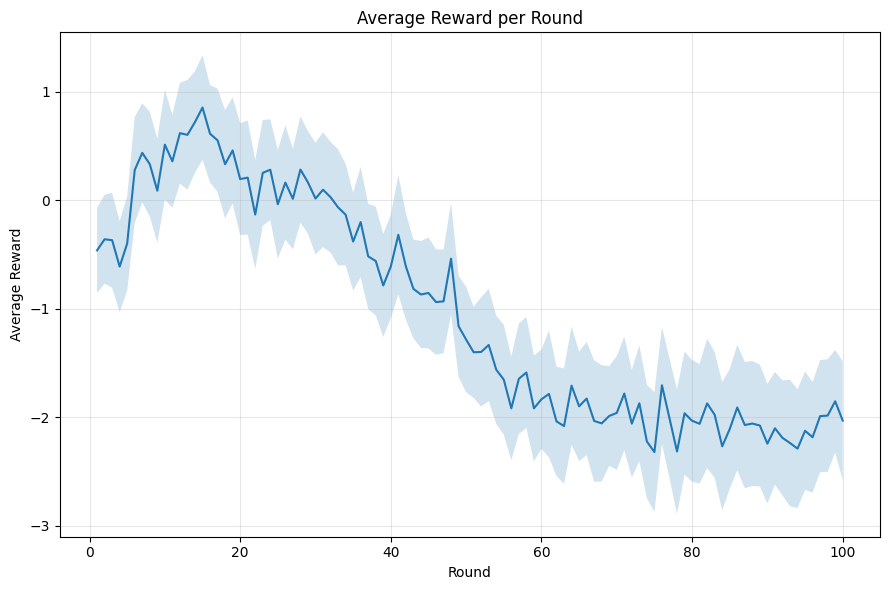

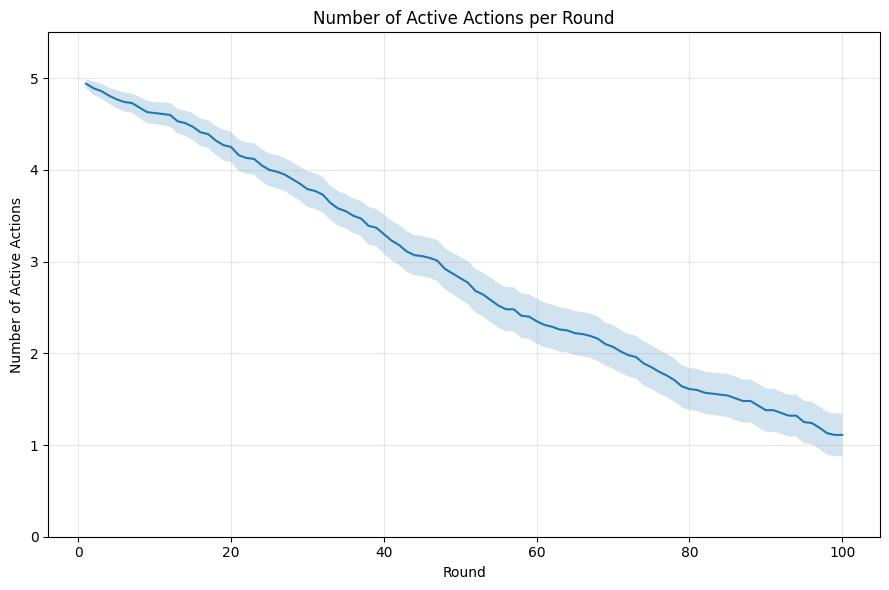

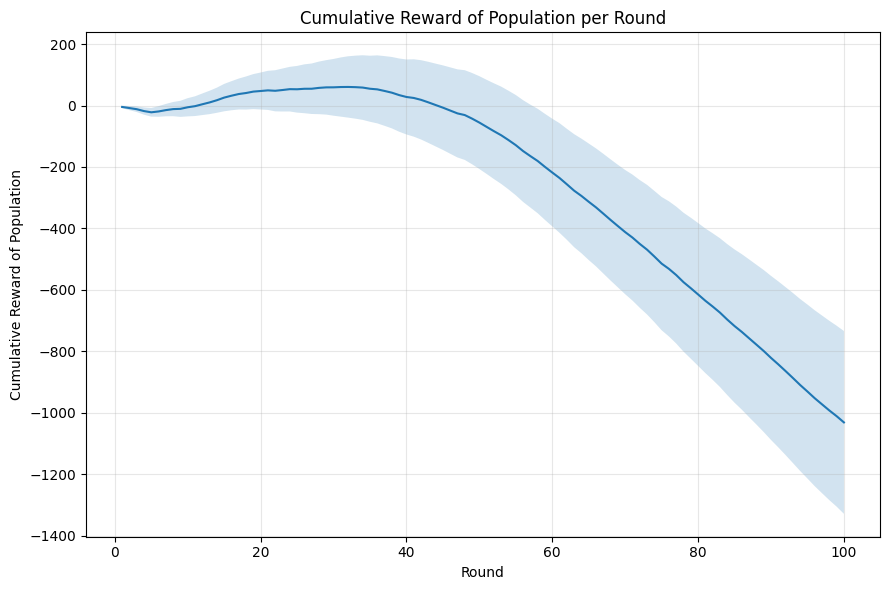

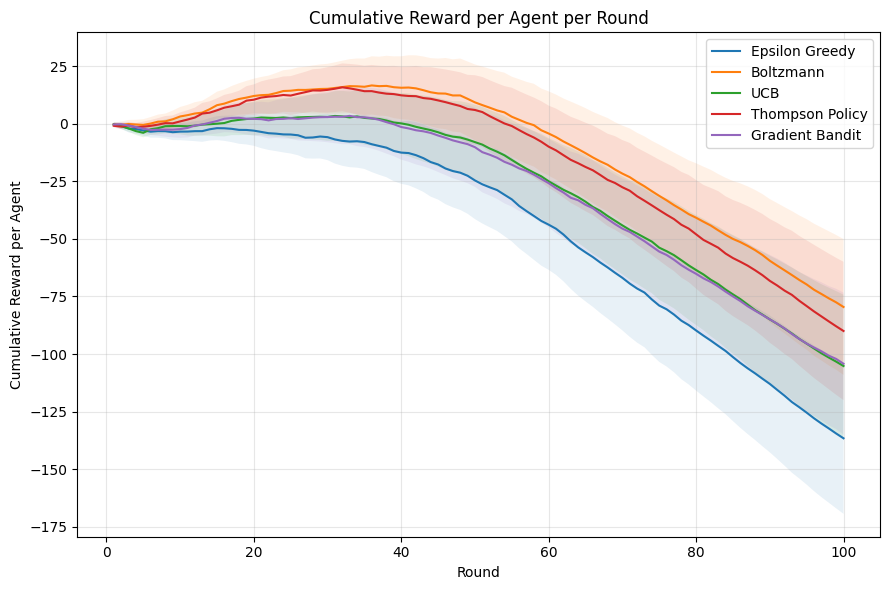

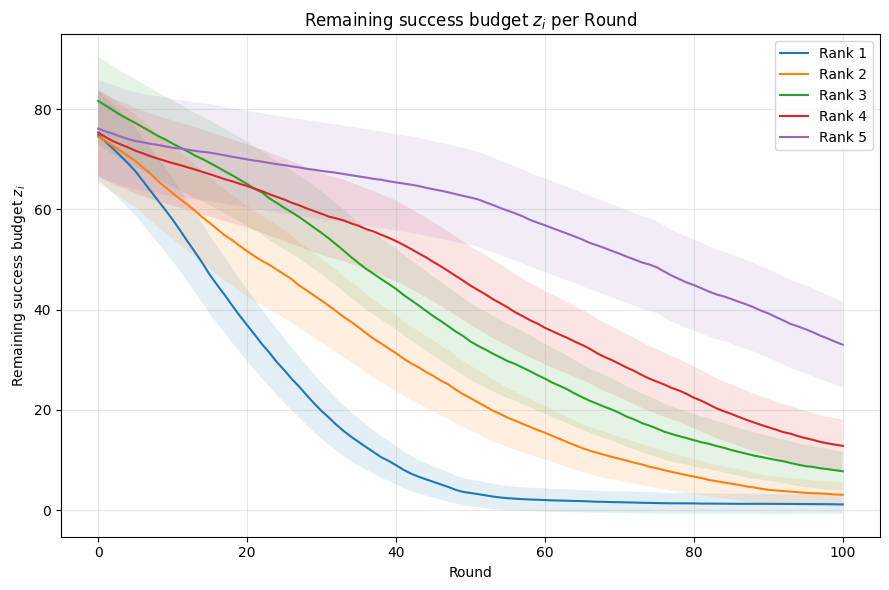

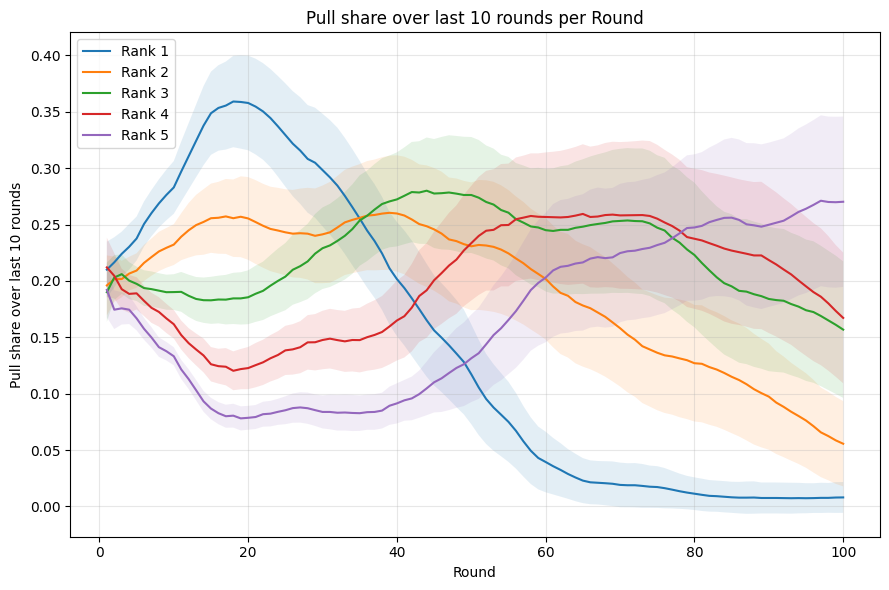

In [ ]:
MIN_P_I = 0.05
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

p_res = run_and_report(policies)
MIN_P_I = 0.2

Unlike what I expected the cumulative reward is much less. The reason is probably because there is less probability of getting a positive reward from a terrible action, which seems to be chosen a lot of the times so even in this environment the non-optimal action is selected many of the times..